__Dataset__: [Link](https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset)

In [1]:
import numpy as np
import pandas as pd
# from typing import overload
import re
import string
from utils.constants import chat_words
import os
import ast

import nltk
NLTK_DIR = os.path.abspath("./env/nltk_data")
# Tokenizer
nltk.download('punkt', download_dir=NLTK_DIR, raise_on_error=True, quiet=True)
nltk.download('punkt_tab', download_dir=NLTK_DIR, raise_on_error=True, quiet=True)
# Correct spelling
nltk.download('words', download_dir=NLTK_DIR, raise_on_error=True, quiet=True)
# stopword removal
nltk.download('stopwords', download_dir=NLTK_DIR, raise_on_error=True, quiet=True)
# download wordnet
nltk.download('wordnet', download_dir=NLTK_DIR, raise_on_error=True, quiet=True)

nltk.data.path.insert(0, NLTK_DIR)

from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.metrics.distance import jaccard_distance
from nltk.util import ngrams
from nltk.corpus import words, stopwords
from nltk.stem.porter import PorterStemmer
from nltk.stem import WordNetLemmatizer

from collections import Counter

from sklearn.preprocessing import OneHotEncoder, LabelEncoder

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import (pack_padded_sequence, pad_packed_sequence)

#### Preprocessing

In [3]:
DATAPATH = 'data/spam.csv'

dataset_v1 = pd.read_csv(
    DATAPATH,
    header=0,
    usecols=[0, 1],
    names=["label", "message"],
    encoding="utf-8",
    encoding_errors="ignore"
)

df = dataset_v1.copy()
# df = df.dropna(subset=["label", "message"]).copy()
# df["label"] = df["label"].astype(str).str.strip().str.lower()
# df["message"] = df["message"].astype(str)

# print(f"Messages: {len(df):,}")
# print("Label counts:", df["label"].value_counts().to_dict())
# df.sample(5)


#### (EDA)

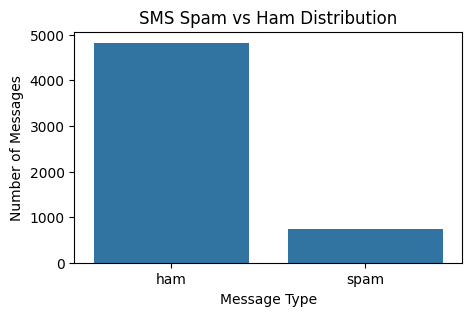

In [4]:
plt.figure(figsize=(5, 3))

sns.countplot(data=df, x='label')
plt.title('SMS Spam vs Ham Distribution')
plt.xlabel('Message Type')
plt.ylabel('Number of Messages')

plt.show()

In [5]:
df['message_length'] = df['message'].apply(len)
df.sample(3)

,label,message,message_length
252,ham,What you doing?how are you?,27
5474,ham,Where's mummy's boy ? Is he being good or bad ...,122
3798,ham,"Actually nvm, got hella cash, we still on for ...",61


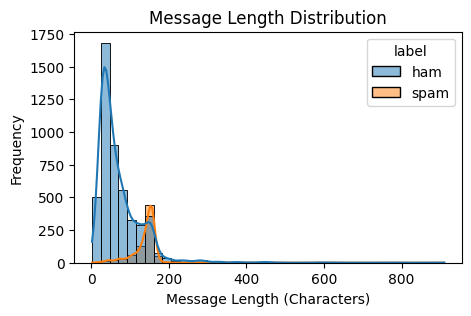

In [6]:
plt.figure(figsize=(5, 3))

sns.histplot(
    data=df,
    x='message_length',
    hue='label',
    bins=40,
    kde=True
)

plt.title('Message Length Distribution')
plt.xlabel('Message Length (Characters)')
plt.ylabel('Frequency')

plt.show()

#### Text-preprocessing functions

In [7]:
def remove_number_middle_of_text(text):
    pattern = re.compile(r'[a-zA-Z]+')
    text = pattern.sub(r"", text)
    return " ".join(text)

def remove_htmltags(text):
    pattern = re.compile(r"<.*?>")
    return pattern.sub(r"", text)

def remove_urls(text):
    pattern = re.compile(r"https?:\/\/\S+|www\.\S+")
    return pattern.sub(r"", text)

def remove_punctuations(text):
    excluded_punctuations = string.punctuation
    return text.translate(str.maketrans(" ", " ", excluded_punctuations))

def eloborate_chat_conversion(texts):
    new_text = []
    token_words = texts.split()
    
    for word in token_words:
        key = word.upper()
        if key in chat_words:
            new_text.append(chat_words[key])
        else:
            new_text.append(word)
    return " ".join(new_text)


def corrected_spelling(texts):
    results = []
    correct_words = [w.lower() for w in words.words()]
    correct_set = set(correct_words)
    text_tokens = texts.split()
    
    for word in text_tokens:
        lower_word = word.lower()
        # keep the correctly spelled words
        if lower_word in correct_set or not lower_word.isalpha() or len(lower_word) < 2:
            results.append(lower_word)
            continue
        
        incorrect_bigrams = set(ngrams(lower_word, 2))
        best_score, best_match = 1.0, word
        
        for w in correct_words:
            if w[0] == lower_word[0]:
                correct_bigrams = set(ngrams(w, 2))
                score = jaccard_distance(incorrect_bigrams, correct_bigrams)
                if score < best_score:
                    best_score, best_match = score, w
        results.append(best_match)
    return " ".join(results)

def remove_stopwords(texts):
    cleaned = []
    text_tokens = texts.split()
    stop_words = set(stopwords.words('english'))
    for word in text_tokens:
        # word is already lowered
        if word and word not in stop_words:
            cleaned.append(word)
    return " ".join(cleaned)


def remove_emoji(texts):
    text_tokens = texts.split()
    text = " ".join(text_tokens)
    emoji_pattern = re.compile(
        "["
        "\U0001F600-\U0001F64F"  # emoticons
        "\U0001F300-\U0001F5FF"  # symbols & pictographs
        "\U0001F680-\U0001F6FF"  # transport & map symbols
        "\U0001F1E0-\U0001F1FF"  # flags
        "\U00002700-\U000027BF"  # dingbats
        "\U000024C2-\U0001F251"
        "]+",
        flags=re.UNICODE
    )
    texts = emoji_pattern.sub(r'', text)
    return texts


def stemming_words(text_tokens):
    ps = PorterStemmer()
    stemmed_words = []
    return [stemmed_words.append(ps.stem(word)) for word in text_tokens]

def lemmatize_words(text_tokens):
    lemmatized_words = []
    wordnet_lemmatizer = WordNetLemmatizer()
    for word in text_tokens:
        lemmatized_words.append(wordnet_lemmatizer.lemmatize(word, pos='v'))
    return lemmatized_words


def text_preprocessing(text):
    # lowercasing
    text = text.lower()
        
    # remove html tags
    text = remove_htmltags(text)
    
    # remove urls from text
    text = remove_urls(text)
    
    text = remove_punctuations(text)
    
    text = eloborate_chat_conversion(text)
    
    text = corrected_spelling(text)
    
    text = remove_stopwords(text)
    
    text = remove_emoji(text)
    
    tokenized_text = word_tokenize(text)
    
    # tokenized_text = stemming_words(tokenized_text)
    
    tokenized_text = lemmatize_words(tokenized_text)
    
    
    return tokenized_text

In [ ]:
# # text_preprocessing("""helo amzing ADIH <p>hello world</p> <br/> https://helo_texts.com
# # https://www.helo_texts.com
# # http://localhost:5000"""+df['message'][0])
# df['tokens'] = df['message'].apply(text_preprocessing)
# corpus_tokens = df['tokens'].tolist()

#### Remove the empty tokens

In [ ]:
# null_indices = df[df['tokens'].apply(lambda x: len(x) == 0)].index
# df.drop(null_indices, inplace=True)

In [ ]:
# ' '.join(df['tokens'].iloc[0])

'go juror point crazy available bugi n great world la e buffet cine get amores wat'

#### For deleting the memory using gc

In [6]:
# import gc

# # del X_train
# gc.collect()

In [ ]:
# df['cleaned_text'] = df['tokens'].apply(' '.join)
# DATA_DIR = os.path.abspath("./data")
# df.to_csv(f"{DATA_DIR}/processed.csv", index=True)

#### Processed data

Need to fix the cleaned text

In [8]:
df = pd.read_csv(os.path.abspath("./data/processed_v1.csv"))
df.sample(5)

,Unnamed: 0,label,message,tokens,cleaned_text
5165,5175,ham,Raji..pls do me a favour. Pls convey my Birthd...,"['rajiv', 'favous', 'ply', 'convey', 'birthday...",rajiv favous ply convey birthday wish nim ply ...
420,422,ham,Siva is in hostel aha:-.,"['siva', 'hostel', 'aha']",siva hostel aha
5377,5387,ham,I will be gentle baby! Soon you will be taking...,"['gentle', 'baby', 'soon', 'take', 'lilt', 'in...",gentle baby soon take lilt inch deep inside ti...
1731,1735,ham,Why tired what special there you had,"['tire', 'special']",tire special
3926,3932,ham,"Playin space poker, u?","['playingly', 'space', 'poker']",playingly space poker


### Features and targets

In [9]:
def string_list_to_list(string_list: str):
    return ast.literal_eval(string_list)


X_text = df['cleaned_text'].fillna("").astype(str)
X_token = df['tokens'].apply(string_list_to_list)

y = df['label']

In [10]:
y.value_counts()

label
ham     4815
spam     747
Name: count, dtype: int64

### Encode the label manually

In [11]:
label_mapping = {
    "spam": 0,
    "ham": 1
}

y = df["label"].str.lower().map(label_mapping).values

#### Train, validation and Test data

In [12]:
# with `cleaned_text` columns
# X_train, X_temp, y_train, y_temp = train_test_split(X_text, y, test_size=0.3, random_state=42, stratify=y, shuffle=True)
# X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp, shuffle=True)

X_train, X_temp, y_train, y_temp = train_test_split(X_token, y, test_size=0.3, random_state=42, stratify=y, shuffle=True)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp, shuffle=True)

print(f'X_train: {X_train.shape}')
print(f'y_train: {y_train.shape}')
print('\n')
print(f'X_val: {X_val.shape}')
print(f'y_val: {y_val.shape}')
print('\n')
print(f'X_test: {X_test.shape}')
print(f'y_test: {y_test.shape}')

X_train: (3893,)
y_train: (3893,)


X_val: (834,)
y_val: (834,)


X_test: (835,)
y_test: (835,)


In [13]:
X_train.tolist()[:5][1]

['hah', 'figure', 'well', 'find', 'piece', 'priscilla', 'bowl']

In [ ]:
# le = LabelEncoder()
# le.classes_ = np.array(['spam', 'ham'])

# y_train_num = le.fit_transform(y_train)
# y_val_num = le.transform(y_val)
# y_test_num = le.transform(y_test)

In [14]:
y_train

array([1, 1, 1, ..., 0, 1, 1], shape=(3893,))

## Train

#### Build vocabulary

In [15]:
PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"

PAD_IDX = 0
UNK_IDX = 1

vocab = {
    PAD_TOKEN: PAD_IDX,
    UNK_TOKEN: UNK_IDX
}


# when using dataframes `cleaned_text` columns
# for sentence in X_train.fillna("").tolist():
#     for token in str(sentence).split():
#         if token not in vocab:
#             vocab[token] = len(vocab)


# when using dataframes `tokens` columns
for token_sentence in X_train.tolist():
    for token in token_sentence:
        if token not in vocab:
            vocab[token] = len(vocab)


In [16]:
print("Vocabulary size:", len(vocab))

Vocabulary size: 5756


In [17]:
# when using dataframes `tokens` columns
def text_to_indices(sentence, vocab):
    numerical_sentences = []
    for token in sentence:
        token_id = vocab.get(token, UNK_IDX)
        numerical_sentences.append(token_id)
    return numerical_sentences


def convert_to_numerical_sentence(texts: list|str):
    # print(f"convert_to_numerical_sentence:texts {texts}")
    X_train_numerical_sentences = []

    if isinstance(texts, str):
        texts_indices = text_to_indices(texts, vocab)
        return texts_indices
    else:
        for sentence in texts:
            texts_indices = text_to_indices(sentence, vocab)
            X_train_numerical_sentences.append(texts_indices)
        return X_train_numerical_sentences

In [18]:
X_train_numerical_sentences = convert_to_numerical_sentence(X_train.tolist())
X_train_numerical_sentences[:3]

[[2, 3, 4, 5, 6, 2, 7, 8, 9, 10, 11],
 [12, 13, 14, 15, 16, 17, 18],
 [19, 20, 21, 22, 23, 24, 25]]

#### Padding

In [19]:
TRAIN_SEQ_MAX_LEN = max([ len(seq) for seq in X_train_numerical_sentences ])

def padded_numerical_sentences(numeric_sentences):

    if len(numeric_sentences) == 0:
        return [], []

    # Detect a single numerical sentence
    if isinstance(numeric_sentences[0], int):
        sequences = [numeric_sentences]
        is_single = True

    else:
        sequences = numeric_sentences
        is_single = False

    padded_sequences = []
    actual_lengths = []

    for seq in sequences:

        if not isinstance(seq, (list, tuple)):
            raise TypeError(
                f"Expected a list of token indices, got {type(seq)}: {seq}"
            )

        # Truncate
        seq = list(seq)[:TRAIN_SEQ_MAX_LEN]

        # Handle empty sequence
        if len(seq) == 0:
            seq = [UNK_IDX]

        # Calculate actual length
        actual_length = len(seq)

        # Padding
        pad_seq = seq + (
            [PAD_IDX] * (TRAIN_SEQ_MAX_LEN - actual_length)
        )

        padded_sequences.append(pad_seq)
        actual_lengths.append(actual_length)

    if is_single:
        return padded_sequences[0], actual_lengths[0]

    return padded_sequences, actual_lengths
    

X_train_padded_seqs, X_train_actual_lengths = padded_numerical_sentences(X_train_numerical_sentences)


In [20]:
len(X_train_padded_seqs)

3893

#### OneHotEncoder

In [ ]:
# all_train_tokens = list({
#     token 
#     for line in X_train.tolist() 
#     if isinstance(line, str) 
#     for token in line.split() 
#     if token and len(token) > 0 and token not in (0, 0.0, "0", "0.0")
# })

In [ ]:
# len(all_train_tokens)
# all_train_tokens_arr = np.array(all_train_tokens).reshape(-1, 1)

In [ ]:
# ohe = OneHotEncoder(sparse_output=True, handle_unknown='ignore', dtype=np.int8)
# ohe.fit(all_train_tokens_arr)

# vocab_size = len(ohe.categories_[0])

# def doc_to_ohe(corpus, ohe_encoder=ohe):
#     ohe_corpus = []
#     for line in corpus.tolist():
#         # 1. Ensure line is a string to avoid AttributeError on floats/NaNs
#         if isinstance(line, str):
#             line_tokens = [
#                 tok for tok in line.split() 
#                 if tok and tok not in (0, 0.0, "0", "0.0")
#             ]
            
#             # 2. Only transform if there are valid tokens left
#             if line_tokens:
#                 ohe_line = ohe_encoder.transform(np.array(line_tokens).reshape(-1, 1)).toarray()
#                 ohe_corpus.append(ohe_line)
                
#     return ohe_corpus


In [ ]:
# X_train_encoded = doc_to_ohe(X_train)

# encoded_max_length = max(len(line) for line in X_train_encoded)
# print(encoded_max_length)


In [ ]:
# X_train_ohe = []

# for ohe_line in X_train_encoded:
#     # Pad each line to the maximum length with zeros
#     padded_line = np.pad(ohe_line, ((0, encoded_max_length - len(ohe_line)), (0, 0)), mode='constant')
#     X_train_ohe.append(padded_line)

In [ ]:
# X_train_ohe[0]

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(79, 6233), dtype=int8)

#### Bag Of Words

In [ ]:
# train_corpus = X_train
# test_corpus = X_test

# cv = CountVectorizer()
# cv_ngram = CountVectorizer(ngram_range=(1, 2))
# X_train_bow = cv.fit_transform(train_corpus)
# X_test_bow = cv.transform(test_corpus)

# X_train_bow_ngram = cv_ngram.fit_transform(train_corpus)
# X_test_bow_ngram = cv_ngram.transform(test_corpus)

In [ ]:
# print(f'After apply the BoW(Bag of Word) the shape: {X_train_bow.shape}')
# print(f'Vocabulary size: {len(cv.vocabulary_)}')
# cv.get_feature_names_out()[1000]

### TF-IDF

In [21]:
X_train[0]

['go',
 'juror',
 'point',
 'crazy',
 'available',
 'bugi',
 'n',
 'great',
 'world',
 'la',
 'e',
 'buffet',
 'cine',
 'get',
 'amores',
 'wat']

In [12]:
# tfidf = TfidfVectorizer()

# X_train_tfidf = tfidf.fit_transform(X_train).toarray()
# X_val_tfidf = tfidf.transform(X_val).toarray()
# X_test_tfidf = tfidf.transform(X_test).toarray()

In [13]:
# len(tfidf.vocabulary_)

5818

In [18]:
# X_train_tfidf[0]

array([0., 0., 0., ..., 0., 0., 0.], shape=(5818,))

#### Torch device

In [22]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f'System device: {device}')

System device: cuda


#### Dataset and Dataloader

In [23]:
class SentimentDataset(Dataset):
    def __init__(self, X, lengths, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.lengths = torch.tensor(
            lengths,
            dtype=torch.long
        )
        self.y = torch.tensor(
            y,
            dtype=torch.float32
        )
        # Validate dimensions
        assert len(self.X) == len(self.lengths) == len(self.y)

        # Validate sequence lengths
        assert torch.all(self.lengths > 0)

        assert torch.all(
            self.lengths <= self.X.size(1)
        ), "Actual sequence length exceeds padded sequence width!"

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return (self.X[idx], self.lengths[idx], self.y[idx])



#### Prepare Sequence

In [24]:
X_train_numerical_sentences[:3]
# X_train_padded_seqs.shape

[[2, 3, 4, 5, 6, 2, 7, 8, 9, 10, 11],
 [12, 13, 14, 15, 16, 17, 18],
 [19, 20, 21, 22, 23, 24, 25]]

### Word2Vec

In [25]:
from gensim.models import KeyedVectors
import gensim.downloader as api
word2vec_model = api.load('word2vec-google-news-300')
# # wv_model = KeyedVectors.load_word2vec_format('GoogleNews-vectors-negative300.bin.gz', binary=True, limit=500000)

In [35]:
print(f'Word2Vec Vocabulary: {len(word2vec_model)}')
print(f'Vocabulary(text-to-index): {len(vocab)}')
print(f'Embedding dimension: {word2vec_model.vector_size}')

vector = word2vec_model['test']
print(f'Vector shape: {vector.shape}')

Word2Vec Vocabulary: 3000000
Vocabulary(text-to-index): 5756
Embedding dimension: 300
Vector shape: (300,)


#### Word2Vec embedding matrix

In [36]:
embedding_dim = 300
# vocab
vocab_size = len(vocab)
embedding_matrix = np.zeros(shape=(vocab_size, embedding_dim), dtype=np.float32)

found_words = 0
missing_words = 0


for word, idx in vocab.items():
    if word == PAD_TOKEN:
        continue
    vector = None
    if word in word2vec_model:
        vector = word2vec_model[word]
    # elif word.upper() in word2vec_model:
    #     vector = word2vec_model[word.upper()]
    
    
    if vector is not None:
        embedding_matrix[idx] = vector
        found_words += 1
    else:
        embedding_matrix[idx] = np.random.normal(0, 0.1, embedding_dim)
        missing_words += 1


print(f'Embedding matrix: {embedding_matrix.shape}')
print(f'Found words: {found_words}')
print(f'Missing words: {missing_words}')

Embedding matrix: (5756, 300)
Found words: 3929
Missing words: 1826


In [37]:
len(X_train_padded_seqs)

print(f'Shape of X_train_padded_seqs: (3893 x 79)')

Shape of X_train_padded_seqs: (3893 x 79)


In [38]:
train_dataset = SentimentDataset(X_train_padded_seqs, X_train_actual_lengths, y_train)
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)

embedding_weights = torch.tensor(embedding_matrix, dtype=torch.float32)

In [39]:
for num_seq, lengths, labels in train_dataloader:
    print(f'{num_seq.shape}, {lengths.shape}, {labels.shape}')
    break

torch.Size([32, 73]), torch.Size([32]), torch.Size([32])


## Model

In [40]:

class SentimentNet(nn.Module):
    def __init__(self, vocab_size, embedding_dim=300, hidden_dim=128, dense_dim=128, dropout=0.3):
        super(SentimentNet, self).__init__()
        
        # 1. embeddings
        # self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=0)
        self.embedding = nn.Embedding.from_pretrained(embedding_weights, freeze=False, padding_idx=0)
        
        # 2. Bidirectional LSTM
        self.lstm = nn.LSTM(input_size=embedding_dim, hidden_size=hidden_dim, batch_first=True, bidirectional=True)
        
        # BiLSTM produces hidden_dim * 2 features
        lstm_output_dim = hidden_dim * 2    
        
        # 3. Dropout
        self.dropout1 = nn.Dropout(dropout)
        
        # 4. Dense layer
        self.fc1 = nn.Linear(in_features=lstm_output_dim, out_features=dense_dim)
        self.relu = nn.ReLU()
        
        # 5. Additional dropout
        self.dropout2 = nn.Dropout(dropout)
        
        # 6. Output layer
        self.fc2 = nn.Linear(in_features=dense_dim, out_features=1)
        

    def forward(self, X, lengths):
        lengths_cpu = lengths.cpu()
        lengths_dev = lengths.to(X.device)
        # input - [batch, sequence]
        X = self.embedding(X)
        
        # output - [batch, sequence, embedding_dim]
        # Pack sequences to exclude padding from LSTM processing
        packed = pack_padded_sequence(X, lengths=lengths_cpu, batch_first=True, enforce_sorted=False)
        packed_output, _ = self.lstm(packed)
        
        lstm_output, _ = pad_packed_sequence(packed_output, batch_first=True, total_length=X.size(1))
        
        # output - [batch, sequence, hidden_dim * 2]
        
        # createe a mask for actual tokens
        mask = (
            torch.arange(X.size(1), device=X.device).unsqueeze(0) < lengths_dev.unsqueeze(1)
        )
        mask = mask.unsqueeze(-1)
        
        # masked mean pooling
        masked_output = lstm_output * mask
        
        # pooled = masked_output.sum(dim=1) / lengths.to(device).unsqueeze(1)
        pooled = masked_output.sum(dim=1) / lengths.to(X.device).unsqueeze(1).clamp_min(1)
        
        # output: [batch, hidden_dim * 2]
        
        # Dense transformation
        X = self.dropout1(pooled)
        
        X = self.fc1(X)
        X = self.relu(X)
        X = self.dropout2(X)
        
        # output logits: [batch, 1]
        logits = self.fc2(X)
        
        return logits.squeeze(-1)


In [32]:
vocab_size

5756

In [67]:
model = SentimentNet(
    vocab_size=vocab_size,
    embedding_dim=300,
    hidden_dim=128,
    dense_dim=128,
    dropout=0.3).to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = optim.Adam(params=model.parameters(), lr=0.001)

In [68]:
model

SentimentNet(
  (embedding): Embedding(5756, 300, padding_idx=0)
  (lstm): LSTM(300, 128, batch_first=True, bidirectional=True)
  (dropout1): Dropout(p=0.3, inplace=False)
  (fc1): Linear(in_features=256, out_features=128, bias=True)
  (relu): ReLU()
  (dropout2): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=128, out_features=1, bias=True)
)

In [69]:
model.embedding.weight.shape

torch.Size([5756, 300])

In [70]:
print(f'Input sequence length from dataloader: [32, 79]')
print(f'Input sequence length without padding: 8 or 10 or 11')
print(f'Input sequence length with padding: 79')

Input sequence length from dataloader: [32, 79]
Input sequence length without padding: 8 or 10 or 11
Input sequence length with padding: 79


### Training Loop

In [71]:
epochs = 10

for epoch in range(epochs):
    
    model.train()
    total_loss = 0.0
    
    for token_ids, lengths, labels in train_dataloader:
        token_ids = token_ids.to(device)
        labels = labels.float().to(device)
        
        optimizer.zero_grad()
        
        # forward pass
        logits = model(token_ids, lengths)
        
        # calculate loss
        loss = criterion(logits, labels)
        
        # backpropagation
        loss.backward()
        
        # update parameters
        optimizer.step()
        total_loss += loss.item()
    
    print(f'Epoch: {epoch+1}, Loss: {total_loss / len(train_dataloader):.4f}')


Epoch: 1, Loss: 0.1067
Epoch: 2, Loss: 0.0109
Epoch: 3, Loss: 0.0015
Epoch: 4, Loss: 0.0002
Epoch: 5, Loss: 0.0001
Epoch: 6, Loss: 0.0001
Epoch: 7, Loss: 0.0001
Epoch: 8, Loss: 0.0000
Epoch: 9, Loss: 0.0000
Epoch: 10, Loss: 0.0000


### Inference function

In [24]:
# prediction function

def predict_sentiment(text, model, vocab, device, max_len=200):
    model.eval()

    cleaned_texts = ' '.join(text_preprocessing(text))

    numeric_sentence = convert_to_numerical_sentence(cleaned_texts)

    numeric_sentence = numeric_sentence[:max_len]
    padded_numeric_sentence, current_seq_length = padded_numerical_sentences(numeric_sentence)

    input_tensor = torch.tensor(
        [padded_numeric_sentence],
        dtype=torch.long
    ).to(device)

    length_tensor = torch.tensor([current_seq_length], dtype=torch.long)
    
    with torch.no_grad():
        logits = model(input_tensor, length_tensor)

        ham_probability = torch.sigmoid(logits).item()
        spam_probability = 1 - ham_probability

    prediction = "ham" if ham_probability >= 0.5 else "spam"

    return {
        "text": text,
        "ham_probability": ham_probability,
        "spam_probability": spam_probability,
        "prediction": prediction
    }
    

In [73]:
df[['message', 'label']]

spams = [df.iloc[2]['message'], df.iloc[5557]['message']]
hams = [df.iloc[5558]['message'], df.iloc[5559]['message']]

spams[0]

"Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's"

In [74]:
predict_sentiment(
    text="Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's",
    model=model,
    vocab=vocab,
    device=device,
    max_len=79
)

{'text': "Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's",
 'ham_probability': 2.1096060663694516e-05,
 'spam_probability': 0.9999789039393363,
 'prediction': 'spam'}

#### Save the model

In [75]:
import joblib

model_weights = model.state_dict()
joblib.dump(model_weights, "TextSpamDetect.joblib")


['TextSpamDetect.joblib']

In [41]:
import joblib
loaded_weights = joblib.load("TextSpamDetect.joblib")
loaded_model = SentimentNet(vocab_size=vocab_size).to(device)
loaded_model.load_state_dict(loaded_weights)
loaded_model.eval()

SentimentNet(
  (embedding): Embedding(5756, 300, padding_idx=0)
  (lstm): LSTM(300, 128, batch_first=True, bidirectional=True)
  (dropout1): Dropout(p=0.3, inplace=False)
  (fc1): Linear(in_features=256, out_features=128, bias=True)
  (relu): ReLU()
  (dropout2): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=128, out_features=1, bias=True)
)

In [42]:
predict_sentiment(
    text="Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's",
    model=loaded_model,
    vocab=vocab,
    device=device,
    max_len=79
)

{'text': "Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's",
 'ham_probability': 2.098353797919117e-05,
 'spam_probability': 0.9999790164620208,
 'prediction': 'spam'}

#### Export model to ONNX format

In [85]:
# During training time max_len = 79

# pass the model to CPU
loaded_model = loaded_model.to('cpu')

text = "You are actually win 5000. Just send your bkash pin"
cleaned_text = ' '.join(text_preprocessing(text))
numeric_sentence = convert_to_numerical_sentence(cleaned_text)
numeric_sentence = numeric_sentence[:79]
padded_seq, seq_length = padded_numerical_sentences(numeric_sentence)

input_seq_tensor = torch.tensor([padded_seq], dtype=torch.long)
seq_length_tensor = torch.tensor([seq_length], dtype=torch.long)

input_seq_tensor = input_seq_tensor.to('cpu')
seq_length_tensor = seq_length_tensor.to('cpu')

# Validate input dimensions
assert seq_length <= input_seq_tensor.shape[1]

ex_inputs = (input_seq_tensor, seq_length_tensor)

onnx_program = torch.onnx.export(
    loaded_model,
    ex_inputs,
    'sentiment_model.onnx',
    export_params=True,
    opset_version=17,
    do_constant_folding=True,
    input_names=['input_seq', 'seq_length'],
    output_names=['output'],
    dynamo=False
)
print("ONNX export completed successfully!")

C:\Users\Dhaka-ML-PC\AppData\Local\Temp\ipykernel_7584\3939351108.py:23: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  onnx_program = torch.onnx.export(
c:\Users\Dhaka-ML-PC\anaconda3\Lib\site-packages\torch\onnx\_internal\torchscript_exporter\symbolic_opset9.py:4528: UserWarning: Exporting a model to ONNX with a batch_size other than 1, with a variable length with LSTM can cause an error when running the ONNX model with a different batch size. Make sure to save the model with a batch size of 1, or define the initial states (h0/c0) as inputs of the model. 
  return _generic_rnn(


ONNX export completed successfully!


#### Test the exported model

In [8]:
import onnx
import onnxruntime as ort
import numpy as np


# load the onnx model
# onnx_model = onnx.load('sentiment_model.onnx')

# # validate the onnx graph
# onnx.checker.check_model(onnx_model)
# print('Onnx model validation is successfull!')

# # Load the model on runtime
# session = ort.InferenceSession(
#     'sentiment_model.onnx',
#     providers=['CPUExecutionProvider']
# )

# outputs = session.run(
#     None,
#     { 'input_seq': input_seq_tensor.numpy(), 'seq_length': seq_length_tensor.numpy() }
# )

# #---------------------------------------------------------------
# # Input preparation
# #---------------------------------------------------------------
# text = "You are actually win 5000. Just send your bkash pin"
# cleaned_text = ' '.join(text_preprocessing(text))
# numeric_sentence = convert_to_numerical_sentence(cleaned_text)
# numeric_sentence = numeric_sentence[:79]
# padded_seq, seq_length = padded_numerical_sentences(numeric_sentence)

# input_seq_tensor = torch.tensor([padded_seq], dtype=torch.long)
# seq_length_tensor = torch.tensor([seq_length], dtype=torch.long)
# #---------------------------------------------------------------

# # run the inference
# outputs = session.run(
#     None,
#     { 'input_seq': input_seq_tensor.numpy(), 'seq_length': seq_length_tensor.numpy() }
# )

# print(f'Onnx prediction: {outputs[0]}')

#### Inference function for Onnx

In [46]:

def predict_sentiment_onnx(text, session, max_len=79):
    # 1. Preprocessing
    cleaned_texts = ' '.join(text_preprocessing(text))

    # 2. Convert words into numerical values
    numeric_sentence = convert_to_numerical_sentence(cleaned_texts)

    # 3. Truncate sequence
    numeric_sentence = numeric_sentence[:max_len]

    # 4. Padding
    padded_numeric_sentence, current_seq_length = padded_numerical_sentences(
        numeric_sentence
    )

    # 5. Convert to NumPy arrays
    input_seq = np.array(
        [padded_numeric_sentence],
        dtype=np.int64
    )

    seq_length = np.array(
        [current_seq_length],
        dtype=np.int64
    )

    # 6. ONNX Runtime inference
    outputs = session.run(
        None,
        {
            'input_seq': input_seq,
            'seq_length': seq_length
        }
    )

    # 7. Get logits
    logits = outputs[0]

    # 8. Calculate probabilities
    ham_probability = 1 / (1 + np.exp(-logits)).item()
    spam_probability = 1 - ham_probability

    # 9. Classification
    prediction = "ham" if ham_probability >= 0.5 else "spam"

    return {
        "text": text,
        "ham_probability": ham_probability,
        "spam_probability": spam_probability,
        "prediction": prediction
    }


In [3]:
predict_sentiment_onnx(
    text="WINNER!! You have been selected for a free £1000 prize. Claim now by calling 0900 123 4567 – limited time offer, urgent!",
    session=session,
    max_len=79
)

NameError: name 'predict_sentiment_onnx' is not defined

#### Test with validation

In [48]:
X_val[:5]
y_val[:5]
# ham_texts = [ " ".join(text) for text in X_val[:5] ]

# ham_texts[0]

df.iloc[3107]

Unnamed: 0                                                3112
label                                                      ham
message                        Wat time liao, where still got.
tokens          ['wat', 'tear', 'eye', 'liar', 'still', 'get']
cleaned_text                       wat tear eye liar still get
Name: 3107, dtype: object